# A/B Testing

Run the next cell once to install the packages this notebook uses. Then run the `# datascience` and `# polars` import cells. If an import still fails, restart the kernel and run from the top.


In [ ]:
# setup
# Pins match data8-textbook-polars/requirements.txt.
%pip install -q \
    numpy==2.5.4 \
    pandas==3.1.0 \
    pyarrow==26.0.0 \
    scipy==1.18.1 \
    matplotlib==3.11.2 \
    plotly==7.1.0 \
    datascience==0.18.1 \
    polars==2.1.0 \
    hvplot==0.12.2


In [1]:
# datascience
from datascience import *
import numpy as np

%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')

import warnings
warnings.simplefilter("ignore")

In [2]:
# polars
import polars as pl
import hvplot.polars


## Comparing Two Samples

In [3]:
# datascience
births = Table.read_table('baby.csv')

In [4]:
# polars
births_pl = pl.read_csv('baby.csv', eol_char='\r')


In [5]:
# datascience
births

Birth Weight,Gestational Days,Maternal Age,Maternal Height,Maternal Pregnancy Weight,Maternal Smoker
120,284,27,62,100,False
113,282,33,64,135,False
128,279,28,64,115,True
108,282,23,67,125,True
136,286,25,62,93,False
138,244,33,62,178,False
132,245,23,65,140,False
120,289,25,62,125,False
143,299,30,66,136,True
140,351,27,68,120,False


In [6]:
# polars
births_pl


Birth Weight,Gestational Days,Maternal Age,Maternal Height,Maternal Pregnancy Weight,Maternal Smoker
i64,i64,i64,i64,i64,bool
120,284,27,62,100,false
113,282,33,64,135,false
128,279,28,64,115,true
108,282,23,67,125,true
136,286,25,62,93,false
…,…,…,…,…,…
113,275,27,60,100,false
128,265,24,67,120,false
130,291,30,65,150,true


In [7]:
# datascience
smoking_and_birthweight = births.select('Maternal Smoker', 'Birth Weight')

In [8]:
# polars
smoking_and_birthweight_pl = births_pl.select('Maternal Smoker', 'Birth Weight')


In [9]:
# datascience
smoking_and_birthweight.group('Maternal Smoker')

Maternal Smoker,count
False,715
True,459


In [10]:
# polars
smoking_and_birthweight_pl.group_by('Maternal Smoker').len(name='count').sort('Maternal Smoker')


Maternal Smoker,count
bool,u32
false,715
true,459


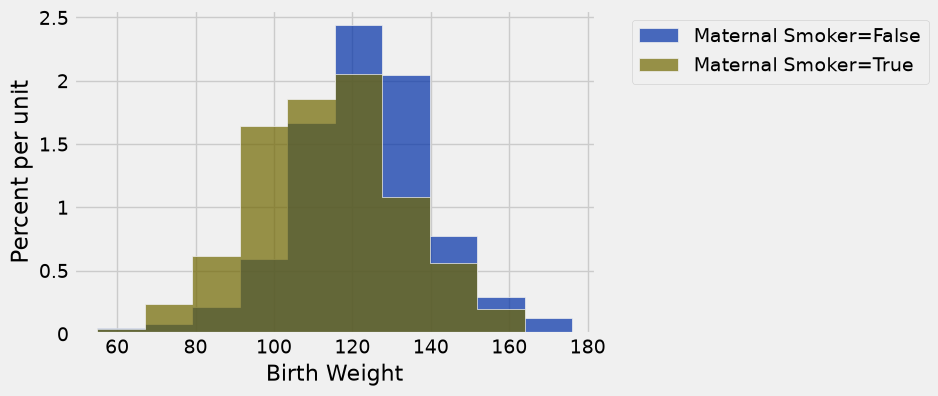

In [11]:
# datascience
smoking_and_birthweight.hist('Birth Weight', group='Maternal Smoker')

In [12]:
# polars
smoking_and_birthweight_pl.hvplot.hist(
    'Birth Weight',
    by='Maternal Smoker',
    bins=10,
    normed=True,
    alpha=0.5,
    color=['#002fa7', '#706700'],
)


:NdOverlay   [Maternal Smoker]
   :Histogram   [Birth Weight]   (Frequency)

## Test Statistic

[Question] What values of our statistic are in favor of the alternative: positive or negative?

In [13]:
# datascience
means_table = smoking_and_birthweight.group('Maternal Smoker', np.average)
means_table

Maternal Smoker,Birth Weight average
False,123.085
True,113.819


In [14]:
# polars
means_table_pl = (
    smoking_and_birthweight_pl
    .group_by('Maternal Smoker')
    .mean()
    .sort('Maternal Smoker')
    .rename({'Birth Weight': 'Birth Weight average'})
)
means_table_pl


Maternal Smoker,Birth Weight average
bool,f64
false,123.085315
true,113.819172


In [15]:
# datascience
means = means_table.column(1)
observed_difference = means.item(1) - means.item(0)
observed_difference

-9.266142572024918

In [16]:
# polars
means_pl = means_table_pl.to_series(1)
observed_difference_pl = means_pl.item(1) - means_pl.item(0)
observed_difference_pl


-9.266142572024918

In [17]:
# datascience
def difference_of_means(table, numeric_label, category_label):
    """
    Takes: 
       - name of table
       - column label of numerical variable
       - column label of categorical variable
       
    Returns: Difference of means of the two groups
    """
    
    #table with the two relevant columns
    reduced = table.select(numeric_label, category_label)  
    
    # table containing group means
    means_table = reduced.group(category_label, np.average)
    
    # array of group means
    means = means_table.column(1)
    
    return means.item(1) - means.item(0)

In [18]:
# polars
def difference_of_means_pl(table, numeric_label, category_label):
    """
    Takes: 
       - name of table
       - column label of numerical variable
       - column label of categorical variable
       
    Returns: Difference of means of the two groups
    """
    
    #table with the two relevant columns
    reduced = table.select(numeric_label, category_label)  
    
    # table containing group means
    means_table_pl = (
        reduced
        .group_by(category_label)
        .mean()
        .sort(category_label)
    )
    
    # array of group means
    means_pl = means_table_pl.to_series(1)
    
    return means_pl.item(1) - means_pl.item(0)


In [19]:
# datascience
difference_of_means(births, 'Birth Weight', 'Maternal Smoker')

-9.266142572024918

In [20]:
# polars
difference_of_means_pl(births_pl, 'Birth Weight', 'Maternal Smoker')


-9.266142572024918

## Random Permutation (Shuffling)

In [21]:
# datascience
staff = Table().with_columns(
    'Names', make_array('Jim', 'Pam', 'Dwight', 'Michael'),
    'Ages', make_array(29, 28, 34, 41)
)

In [22]:
# polars
staff_pl = pl.DataFrame([
    pl.Series('Names', ['Jim', 'Pam', 'Dwight', 'Michael']),
    pl.Series('Ages', [29, 28, 34, 41])
])


In [23]:
# datascience
staff.sample()

Names,Ages
Dwight,34
Pam,28
Jim,29
Jim,29


In [24]:
# polars
staff_pl.sample(n=staff_pl.height, with_replacement=True, shuffle=True)


Names,Ages
str,i64
"""Jim""",29
"""Dwight""",34
"""Jim""",29
"""Pam""",28


In [25]:
# datascience
staff.sample(with_replacement = False)

Names,Ages
Michael,41
Pam,28
Dwight,34
Jim,29


In [26]:
# polars
staff_pl.sample(n=staff_pl.height, with_replacement=False, shuffle=True)


Names,Ages
str,i64
"""Jim""",29
"""Pam""",28
"""Michael""",41
"""Dwight""",34


In [27]:
# datascience
staff.with_column('Shuffled', staff.sample(with_replacement = False).column(0))

Names,Ages,Shuffled
Jim,29,Pam
Pam,28,Jim
Dwight,34,Dwight
Michael,41,Michael


In [28]:
# polars
staff_pl.with_columns(pl.col('Names').shuffle().alias('Shuffled'))


Names,Ages,Shuffled
str,i64,str
"""Jim""",29,"""Pam"""
"""Pam""",28,"""Jim"""
"""Dwight""",34,"""Dwight"""
"""Michael""",41,"""Michael"""


## Simulation Under Null Hypothesis

In [29]:
# datascience
smoking_and_birthweight

Maternal Smoker,Birth Weight
False,120
False,113
True,128
True,108
False,136
False,138
False,132
False,120
True,143
False,140


In [30]:
# polars
smoking_and_birthweight_pl


Maternal Smoker,Birth Weight
bool,i64
false,120
false,113
true,128
true,108
false,136
…,…
false,113
false,128
true,130


In [31]:
# datascience
shuffled_labels = smoking_and_birthweight.sample(with_replacement=False).column('Maternal Smoker')

In [32]:
# polars
shuffled_labels_pl = smoking_and_birthweight_pl.select(pl.col('Maternal Smoker').shuffle()).to_series(0)


In [33]:
# datascience
original_and_shuffled = smoking_and_birthweight.with_column(
    'Shuffled Label', shuffled_labels
)

In [34]:
# polars
original_and_shuffled_pl = smoking_and_birthweight_pl.with_columns(shuffled_labels_pl.alias('Shuffled Label'))


In [35]:
# datascience
original_and_shuffled

Maternal Smoker,Birth Weight,Shuffled Label
False,120,False
False,113,False
True,128,True
True,108,False
False,136,False
False,138,False
False,132,True
False,120,False
True,143,False
False,140,True


In [36]:
# polars
original_and_shuffled_pl


Maternal Smoker,Birth Weight,Shuffled Label
bool,i64,bool
false,120,true
false,113,false
true,128,false
true,108,false
false,136,true
…,…,…
false,113,true
false,128,false
true,130,false


In [37]:
# datascience
difference_of_means(original_and_shuffled, 'Birth Weight', 'Shuffled Label')

1.0756890168654962

In [38]:
# polars
difference_of_means_pl(original_and_shuffled_pl, 'Birth Weight', 'Shuffled Label')


0.456824656824665

In [39]:
# datascience
difference_of_means(original_and_shuffled, 'Birth Weight', 'Maternal Smoker')

-9.266142572024918

In [40]:
# polars
difference_of_means_pl(original_and_shuffled_pl, 'Birth Weight', 'Maternal Smoker')


-9.266142572024918

## Permutation Test

In [41]:
# datascience
def one_simulated_difference(table, numeric_label, category_label):
    """
    Takes: 
       - name of table
       - column label of numerical variable
       - column label of categorical variable
       
    Returns: Difference of means of the two groups
    """
    
    # array of shuffled labels
    shuffled_labels = table.sample(with_replacement = False).column(category_label)
    
    # table of numerical variable and shuffled labels
    shuffled_table = table.select(numeric_label).with_column('Shuffled Label', shuffled_labels)
    
    return difference_of_means(shuffled_table, numeric_label, 'Shuffled Label')   

In [42]:
# polars
def one_simulated_difference_pl(table, numeric_label, category_label):
    """
    Takes: 
       - name of table
       - column label of numerical variable
       - column label of categorical variable
       
    Returns: Difference of means of the two groups
    """
    
    # array of shuffled labels
    shuffled_labels_pl = table.select(pl.col(category_label).shuffle()).to_series(0)
    
    # table of numerical variable and shuffled labels
    shuffled_table = table.select(numeric_label).with_columns(shuffled_labels_pl.alias('Shuffled Label'))
    
    return difference_of_means_pl(shuffled_table, numeric_label, 'Shuffled Label')


In [43]:
# datascience
one_simulated_difference(births, 'Birth Weight', 'Maternal Smoker')

-0.49830126300713573

In [44]:
# polars
one_simulated_difference_pl(births_pl, 'Birth Weight', 'Maternal Smoker')


0.5069061657297027

In [45]:
# datascience
differences = make_array()

for i in np.arange(2000):
    new_difference = one_simulated_difference(births, 'Birth Weight', 'Maternal Smoker')
    differences = np.append(differences, new_difference)

In [46]:
# polars
differences_pl = pl.Series('differences', [], dtype=pl.Float64)

for i in range(2000):
    new_difference = one_simulated_difference_pl(births_pl, 'Birth Weight', 'Maternal Smoker')
    differences_pl = pl.concat([differences_pl, pl.Series(differences_pl.name, [new_difference])])


Observed Difference: -9.266142572024918


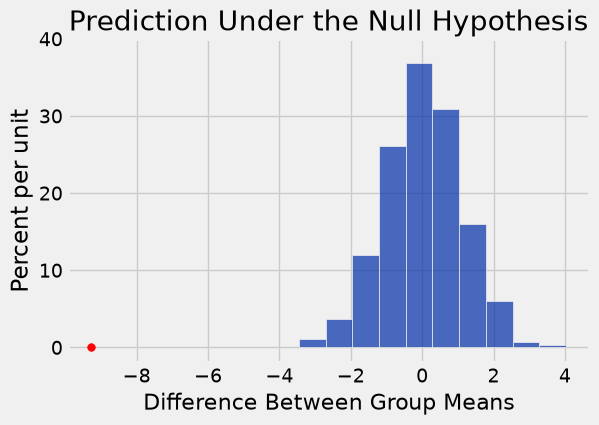

In [47]:
# datascience
Table().with_column('Difference Between Group Means', differences).hist()
plots.ylim(-.02, .4)
plots.scatter(observed_difference, 0, color='red', s=30);
print('Observed Difference:', observed_difference)
plots.title('Prediction Under the Null Hypothesis');

In [48]:
# polars
print('Observed Difference:', observed_difference_pl)
pl.DataFrame({
    'Difference Between Group Means': differences_pl.to_list()
}).hvplot.hist(
    'Difference Between Group Means',
    bins=10,
    normed=True,
    title='Prediction Under the Null Hypothesis',
)


:Overlay
   .Histogram.I :Histogram   [Difference Between Group Means]   (Frequency)
   .Scatter.I   :Scatter   [x]   (y)

Observed Difference: -9.266142572024918
